# Case 5 - Does demand react to price? Elasticity, causality and the supplier's hedge ratio

Energy MBA - Energy Markets Quantitative Analysis (EMQA) - Prof. Daniel Traian Pele

Bucharest University of Economic Studies - Romanian Academy, Institute for Economic Forecasting

In [ ]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/EMQA'):
    if not os.path.isdir('/content/EMQA'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/EMQA.git', '/content/EMQA'], check=True)
    os.chdir('/content/EMQA/cases/C5_demand_elasticity')

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "en"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Paper.** Proșcanu, C., Proșcanu, M. & Pele, D. T. (2025). The price elasticity of electricity demand in Romania.
*Journal of Social and Economic Statistics*, 14(2), 131-141. doi:10.2478/jses-2025-0009

**Why this paper for Lecture 5 (derivatives and hedging).** A supplier that sells at a fixed price hedges its *expected volume*. If customers cut
consumption when prices spike, part of the risk hedges itself; if they do not, the supplier must hedge (almost) the full volume. The elasticity
is therefore an input to the hedge ratio. Complementary research by our group (Shahar, Lessmann & Pele, 2025, arXiv 2507.12331) estimates the causal effect of
US market liberalisation on residential prices, a market-design perspective; this case focuses on Romanian procurement.

**What we do here.** (1) Monthly consumption and price, January 2019 - December 2024 (the paper's sample). (2) Unit-root tests. (3) The paper's
regression of log consumption on log price with seasonal ARMA errors. (4) Granger causality in both directions, lags 1-12. (5) An extension: instrument
the price with the TTF gas price to separate demand from supply. (6) The supplier's minimum-variance hedge ratio.

**Classroom data construction.** The paper took monthly prices and consumption from Ember and Statista; we aggregate ENTSO-E hourly load
(energy-charts.info) to GWh and average the hourly day-ahead price (EUR/MWh) per month.

## 1. Monthly data

72 months
        price  cons_GWh
count   72.00     72.00
mean   112.12   4754.94
std     89.00    413.87
min     24.86   4038.81
25%     51.76   4475.46
50%     86.13   4766.01
75%    141.41   5026.50
max    490.28   5767.42
paper Table 1:
        price     cons
mean  112.13  4803.06
std    88.99   390.28
min    24.76  4100.00
max   490.80  5780.00


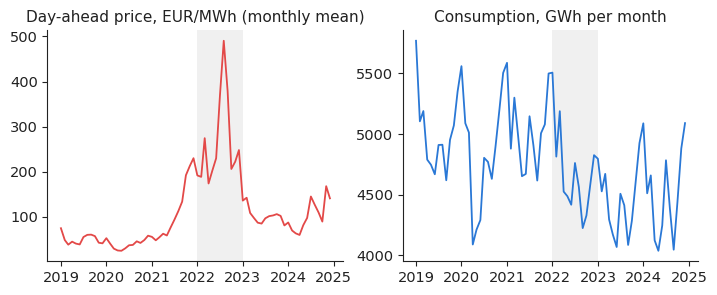

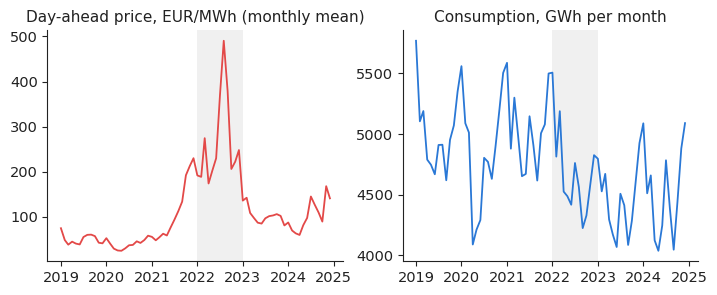

In [2]:
p = cu.prices_hourly()["RO"]; L = cu.generation_ro_hourly()["load"]
h = pd.concat({"p": p, "L": L}, axis=1).dropna()
h.index = h.index.tz_localize(None)
m = pd.DataFrame({"cons_GWh": h.L.resample("MS").sum() / 1000, "price": h.p.resample("MS").mean()})
ttf = cu.ttf_monthly()["ttf_eur_mwh"]
m = m.join(ttf.rename("ttf"))
full = m.loc["2015-01":"2025-12"].dropna()
s = full.loc["2019-01":"2024-12"].copy()          # the paper's sample: 72 months
s["lc"], s["lp"], s["lg"] = np.log(s.cons_GWh), np.log(s.price), np.log(s.ttf)
print(len(s), "months"); print(s[["price", "cons_GWh"]].describe().round(2))
paper_t1 = pd.DataFrame({"price": [112.13, 88.99, 24.76, 490.80], "cons": [4803.06, 390.28, 4100.0, 5780.0]}, index=["mean", "std", "min", "max"])
print("paper Table 1:\n", paper_t1)
def fig_data(lang):
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.0))
    axes[0].plot(s.index, s.price, color=cu.PAL["c8"]); axes[0].set_title(cu.T(lang, "Day-ahead price, EUR/MWh (monthly mean)", "Prețul PZU, EUR/MWh (media lunară)"))
    axes[1].plot(s.index, s.cons_GWh, color=cu.PAL["RO"]); axes[1].set_title(cu.T(lang, "Consumption, GWh per month", "Consumul, GWh pe lună"))
    for a in axes:
        a.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color=cu.MUTED, alpha=0.12, lw=0)
    return fig
cu.save_both(fig_data, "f1_monthly_data")

## 2. Unit roots (Augmented Dickey-Fuller tests)

In [3]:
from statsmodels.tsa.stattools import adfuller
rows = {}
for name, x in [("Price", s.price), ("Consumption", s.cons_GWh)]:
    for d in [0, 1, 2]:
        z = x.copy()
        for _ in range(d):
            z = z.diff()
        st, pv, *_ = adfuller(z.dropna(), autolag="AIC")
        rows[(name, d)] = {"ADF": st, "p": pv}
adf = pd.DataFrame(rows).T
print(adf.round(4))
lab = {"Price": ("Price", "Preț"), "Consumption": ("Consumption", "Consum")}
lev = {0: ("level", "nivel"), 1: ("1st difference", "prima diferență"), 2: ("2nd difference", "a doua diferență")}
t = adf.copy(); t.index = [(f"{lab[a][0]}, {lev[b][0]}", f"{lab[a][1]}, {lev[b][1]}") for a, b in adf.index]
paper_adf = {("Price", 0): 0.3780, ("Price", 1): 0.0001, ("Consumption", 0): 0.5313, ("Consumption", 1): 0.1799, ("Consumption", 2): 0.0001}
t["paper_p"] = [paper_adf.get(i, np.nan) for i in adf.index]
cu.write_table(t, "adf", header=[("Series", "Seria"), ("ADF statistic", "Statistica ADF"), ("$p$-value (ours)", "Valoarea $p$ (replicare)"), ("$p$-value (paper)", "Valoarea $p$ (lucrarea)")],
               digits={"ADF": 3, "p": 4, "paper_p": 4})

                   ADF       p
Price       0  -1.8092  0.3759
            1  -7.3818  0.0000
            2  -7.7292  0.0000
Consumption 0  -1.2770  0.6396
            1  -2.3599  0.1534
            2 -10.8113  0.0000


## 3. The paper's elasticity regression

In [4]:
import statsmodels.api as sm
# log(consumption) = c + beta * log(price) + ARMA(1,1)(1,1)_12 errors   (paper, Table 7: AR(1), SAR(12), MA(1), SMA(12))
sx = sm.tsa.SARIMAX(s.lc, exog=sm.add_constant(s.lp), order=(1, 0, 1), seasonal_order=(1, 0, 1, 12), trend="n").fit(disp=False, maxiter=500)
beta, se = sx.params["lp"], sx.bse["lp"]
print("elasticity (SARIMAX): %.4f (s.e. %.4f), paper: 0.0559 (s.e. 0.0177)" % (beta, se))
# simple OLS with month dummies (no ARMA errors), for comparison
X = pd.get_dummies(s.index.month, prefix="m", drop_first=True, dtype=float).set_index(s.index)
ols = sm.OLS(s.lc, sm.add_constant(pd.concat([s.lp, X], axis=1))).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print("elasticity (OLS + month dummies): %.4f (s.e. %.4f)" % (ols.params["lp"], ols.bse["lp"]))

elasticity (SARIMAX): 0.0644 (s.e. 0.0182), paper: 0.0559 (s.e. 0.0177)
elasticity (OLS + month dummies): -0.0213 (s.e. 0.0134)


first-stage F (gas -> power price): 1382.4
elasticity (2SLS, gas instrument): -0.0231 (s.e. 0.0109)


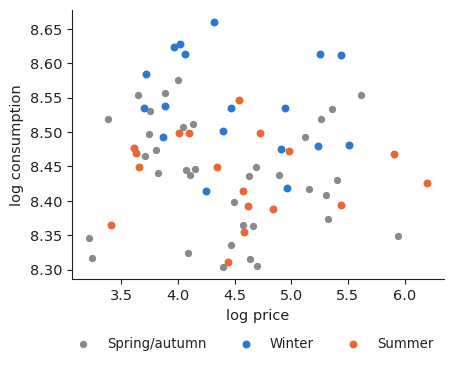

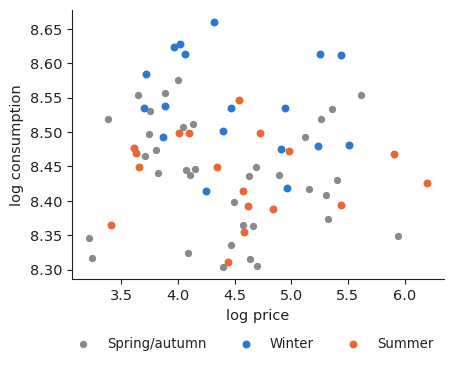

In [5]:
# Extension: two-stage least squares (2SLS). The gas price shifts SUPPLY (cost of the marginal plant) but not household demand directly,
# so it can isolate the demand response to price. Stage 1: lp on lg + month dummies. Stage 2: lc on fitted lp + month dummies.
Z = sm.add_constant(pd.concat([s.lg, X], axis=1)); W = sm.add_constant(pd.concat([s.lp, X], axis=1))
st1 = sm.OLS(s.lp, Z).fit()
F1 = st1.tvalues["lg"] ** 2
What = W.copy(); What["lp"] = st1.fittedvalues
st2 = sm.OLS(s.lc, What).fit()
resid = s.lc - W @ st2.params                                       # residuals with the ACTUAL price
sig2 = (resid ** 2).sum() / (len(s) - W.shape[1])
V = sig2 * np.linalg.inv(What.T @ What)
beta_iv, se_iv = st2.params["lp"], np.sqrt(V.loc["lp", "lp"] if isinstance(V, pd.DataFrame) else V[1, 1])
print("first-stage F (gas -> power price): %.1f" % F1)
print("elasticity (2SLS, gas instrument): %.4f (s.e. %.4f)" % (beta_iv, se_iv))
el = pd.DataFrame({"beta": [0.055866, beta, ols.params["lp"], beta_iv], "se": [0.017736, se, ols.bse["lp"], se_iv]},
                  index=[("Paper (Table 7): SARIMA errors, 2019--2024", "Lucrarea (Tabelul 7): erori SARIMA, 2019--2024"),
                         ("Ours: same specification", "Replicare: aceeași specificație"),
                         ("Ours: OLS + month dummies", "Replicare: MCO + variabile indicatoare lunare"),
                         ("Ours: 2SLS, gas price as instrument", "Replicare: 2SLS, prețul gazelor ca instrument")])
el["t"] = el.beta / el.se
cu.write_table(el, "elasticity", header=[("Estimate", "Estimarea"), ("Elasticity", "Elasticitatea"), ("Std. error", "Eroarea standard"), ("$t$", "$t$")],
               digits={"beta": 4, "se": 4, "t": 2})
def fig_scatter(lang):
    fig, ax = plt.subplots(figsize=(4.8, 3.5))
    win = s.index.month.isin([12, 1, 2]); summ = s.index.month.isin([6, 7, 8])
    ax.scatter(s.lp[~win & ~summ], s.lc[~win & ~summ], s=18, color=cu.MUTED, label=cu.T(lang, "Spring/autumn", "Primăvară/toamnă"))
    ax.scatter(s.lp[win], s.lc[win], s=22, color=cu.PAL["RO"], label=cu.T(lang, "Winter", "Iarnă"))
    ax.scatter(s.lp[summ], s.lc[summ], s=22, color=cu.PAL["DE_LU"], label=cu.T(lang, "Summer", "Vară"))
    ax.set_xlabel(cu.T(lang, "log price", "logaritmul prețului")); ax.set_ylabel(cu.T(lang, "log consumption", "logaritmul consumului"))
    cu.comma_axis(ax, lang, "x", 1); cu.comma_axis(ax, lang, "y", 2)
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_scatter, "f2_scatter")

## 4. Granger causality, lags 1-12

              ours                           paper                
   p_price_to_cons p_cons_to_price p_price_to_cons p_cons_to_price
1           0.5443          0.9181          0.1349          0.8323
2           0.7298          0.5320          0.2267          0.3498
3           0.5718          0.0125          0.6035          0.4096
4           0.3124          0.0141          0.8183          0.5284
5           0.3278          0.0178          0.9044          0.5672
6           0.1936          0.0403          0.8497          0.4156
7           0.3323          0.1413          0.9068          0.0090
8           0.4556          0.0284          0.8873          0.0166
9           0.6239          0.0653          0.7022          0.0137
10          0.3580          0.0626          0.6782          0.0089
11          0.1454          0.2215          0.3130          0.0165
12          0.4525          0.0658          0.1226          0.0053


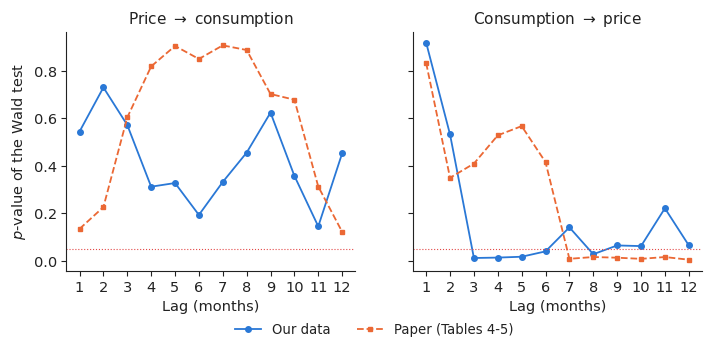

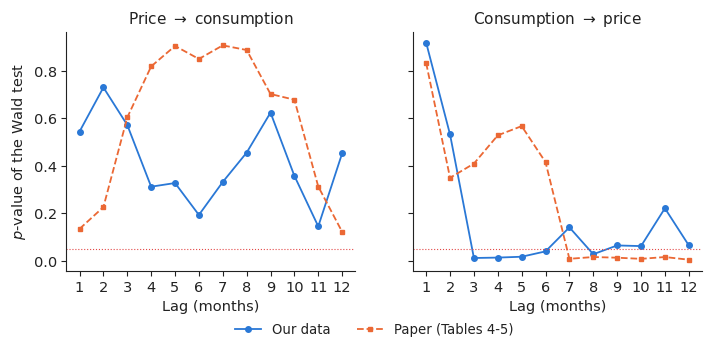

In [6]:
from statsmodels.tsa.api import VAR
dd = pd.DataFrame({"dp": s.lp.diff(), "dc": s.lc.diff()}).dropna()
gc = []
for k in range(1, 13):
    v = VAR(dd).fit(k)
    gc.append({"lag": k, "p_price_to_cons": v.test_causality("dc", ["dp"], kind="wald").pvalue,
               "p_cons_to_price": v.test_causality("dp", ["dc"], kind="wald").pvalue})
gc = pd.DataFrame(gc).set_index("lag")
paper_gc = pd.DataFrame({"p_price_to_cons": [0.1349, 0.2267, 0.6035, 0.8183, 0.9044, 0.8497, 0.9068, 0.8873, 0.7022, 0.6782, 0.3130, 0.1226],
                         "p_cons_to_price": [0.8323, 0.3498, 0.4096, 0.5284, 0.5672, 0.4156, 0.0090, 0.0166, 0.0137, 0.0089, 0.0165, 0.0053]}, index=range(1, 13))
print(pd.concat({"ours": gc, "paper": paper_gc}, axis=1).round(4))
def fig_granger(lang):
    fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.1), sharey=True)
    for a, col, ttl in [(axes[0], "p_price_to_cons", ("Price $\\rightarrow$ consumption", "Preț $\\rightarrow$ consum")),
                        (axes[1], "p_cons_to_price", ("Consumption $\\rightarrow$ price", "Consum $\\rightarrow$ preț"))]:
        a.plot(gc.index, gc[col], color=cu.PAL["RO"], marker="o", ms=4, label=cu.T(lang, "Our data", "Datele cursului"))
        a.plot(paper_gc.index, paper_gc[col], color=cu.PAL["DE_LU"], marker="s", ms=3.5, ls="--", label=cu.T(lang, "Paper (Tables 4-5)", "Lucrarea (Tabelele 4-5)"))
        a.axhline(0.05, color=cu.EVENT, lw=0.8, ls=":")
        a.set_title(cu.T(lang, *ttl)); a.set_xlabel(cu.T(lang, "Lag (months)", "Decalajul (luni)")); a.set_xticks(range(1, 13))
    axes[0].set_ylabel(cu.T(lang, "$p$-value of the Wald test", "Valoarea $p$ a testului Wald"))
    cu.comma_axis(axes[0], lang, "y", 1)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_granger, "f3_granger")

## 5. Decision: the supplier's hedge ratio

corr(volume surprise, price) = -0.308 | h* = 0.931 | risk reduction at h* (in sample): 92.1 %
h* estimated on 01.2016 - 12.2020: 1.061 | risk reduction on 01.2021 - 12.2025 (out of sample): 81.3 %


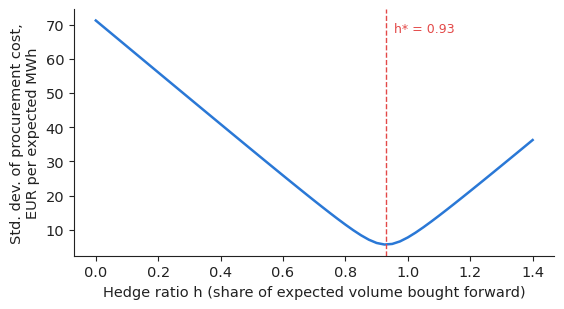

In [7]:
# A supplier sells to households at a fixed price and buys at the monthly spot price P. It can buy forward h x (expected volume) at a fixed price F.
# Procurement cost C = Q*P - h*EQ*(P - F). With F fixed, Var(C) is minimised at h* = Cov(Q*P, P) / (EQ * Var(P)).
# Expected volume EQ = same month of the previous year (what the supplier knows when it hedges). Sample: 2016-2025.
q = full.cons_GWh; pr = full.price
EQ = q.shift(12)
d = pd.DataFrame({"q": q / EQ, "p": pr}).dropna()                # q = actual / expected volume (1 = as planned)
cost = lambda hh: (d.q * d.p - hh * (d.p - d.p.mean()))           # cost per expected MWh, F = sample mean (any constant gives the same variance)
hs = np.linspace(0, 1.4, 57)
sd_cost = np.array([cost(hh).std() for hh in hs])
h_star = np.cov(d.q * d.p, d.p)[0, 1] / d.p.var()
corr_qp = d.q.corr(d.p)
red = 100 * (1 - cost(h_star).std() / cost(0).std())                # in sample: h* estimated and evaluated on the same months
print("corr(volume surprise, price) = %.3f | h* = %.3f | risk reduction at h* (in sample): %.1f %%" % (corr_qp, h_star, red))
# out-of-sample check: estimate h* on the first half of the months only, apply it to the second half
d_in, d_out = d.iloc[:len(d) // 2], d.iloc[len(d) // 2:]
h_in = np.cov(d_in.q * d_in.p, d_in.p)[0, 1] / d_in.p.var()
c_out = lambda hh: d_out.q * d_out.p - hh * (d_out.p - d_out.p.mean())
red_oos = 100 * (1 - c_out(h_in).std() / c_out(0).std())
print("h* estimated on %s - %s: %.3f | risk reduction on %s - %s (out of sample): %.1f %%"
      % (d_in.index[0].strftime("%m.%Y"), d_in.index[-1].strftime("%m.%Y"), h_in, d_out.index[0].strftime("%m.%Y"), d_out.index[-1].strftime("%m.%Y"), red_oos))
def fig_hedge(lang):
    fig, ax = plt.subplots(figsize=(6.2, 3.2))
    ax.plot(hs, sd_cost, color=cu.PAL["RO"], lw=1.8)
    ax.axvline(h_star, color=cu.PAL["c8"], ls="--", lw=1)
    ax.text(h_star, sd_cost.max() * 0.95, "  h* = " + cu.fmt(h_star, 2, lang), color=cu.PAL["c8"], fontsize=9)
    ax.set_xlabel(cu.T(lang, "Hedge ratio h (share of expected volume bought forward)", "Raportul de acoperire h (partea din volumul așteptat cumpărată la termen)"))
    ax.set_ylabel(cu.T(lang, "Std. dev. of procurement cost,\nEUR per expected MWh", "Abaterea standard a costului de achiziție,\nEUR pe MWh așteptat"))
    cu.comma_axis(ax, lang, "x", 1)
    return fig
cu.save_both(fig_hedge, "f4_hedge_ratio", headline=True)
cu.write_numbers({
    "nMonths": len(s), "meanPrice": s.price.mean(), "meanCons": s.cons_GWh.mean(), "maxPrice": s.price.max(),
    "beta": beta, "se": se, "betaOLS": ols.params["lp"], "seOLS": ols.bse["lp"], "betaIV": beta_iv, "seIV": se_iv, "Ffirst": F1,
    "pPCmin": gc.p_price_to_cons.min(), "pCPmin": gc.p_cons_to_price.min(), "lagCPmin": int(gc.p_cons_to_price.idxmin()),
    "nSigCP": int((gc.p_cons_to_price < 0.05).sum()), "nSigPC": int((gc.p_price_to_cons < 0.05).sum()),
    "corrQP": corr_qp, "hStar": h_star, "riskRed": red, "nHedge": len(d), "hIn": h_in, "riskRedOOS": red_oos,
    "inStart": (f"{d_in.index[0]:%B %Y}", f"{d_in.index[0]:%m.%Y}"), "inEnd": (f"{d_in.index[-1]:%B %Y}", f"{d_in.index[-1]:%m.%Y}"),
    "outStart": (f"{d_out.index[0]:%B %Y}", f"{d_out.index[0]:%m.%Y}"), "outEnd": (f"{d_out.index[-1]:%B %Y}", f"{d_out.index[-1]:%m.%Y}"),
    "adfPriceLev": adf.loc[("Price", 0), "p"], "adfConsLev": adf.loc[("Consumption", 0), "p"], "adfConsDiff": adf.loc[("Consumption", 1), "p"],
}, digits={"beta": 4, "se": 4, "betaOLS": 4, "seOLS": 4, "betaIV": 4, "seIV": 4, "Ffirst": 1, "pPCmin": 3, "pCPmin": 3,
           "corrQP": 2, "hStar": 2, "riskRed": 1, "hIn": 2, "riskRedOOS": 1, "adfPriceLev": 3, "adfConsLev": 3, "adfConsDiff": 3, "meanPrice": 1, "meanCons": 0, "maxPrice": 1})

In [8]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=3: cu.fmt(float(v), nd, lang).replace("-", "$-$")
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t("\\textbf{Price elasticity of Romanian demand} (Proșcanu, Proșcanu \\& Pele, 2025, JSES): elasticity 0.056 (small, positive; Table~7); Granger causality runs from consumption to price, not back (Tables~4--5).",
          "\\textbf{Elasticitatea cererii de energie electrică în România} (Proșcanu, Proșcanu și Pele, 2025, JSES): elasticitate de 0,056 (mică și pozitivă; Tabelul~7); cauzalitatea Granger merge de la consum la preț, nu invers (Tabelele~4--5)."),
        t(f"Our replication on the same {len(s)} months: {F(beta)}; with gas as an instrument {F(beta_iv)} --- demand barely reacts to price either way.",
          f"Replicarea noastră pe aceleași {len(s)} de luni: {F(beta)}; cu prețul gazelor ca instrument, {F(beta_iv)} --- cererea aproape nu reacționează la preț."),
        t(f"Decision: no natural hedge --- a fixed-price supplier should buy forward $\\approx${F(h_star, 2)} of expected volume (risk cut {F(red, 0)}\\,\\% in sample; out of sample, $h^*$ = {F(h_in, 2)} from {d_in.index[0].year}--{d_in.index[-1].year} cuts it by {F(red_oos, 0)}\\,\\% in {d_out.index[0].year}--{d_out.index[-1].year}).",
          f"Decizia: nu există o acoperire naturală --- un furnizor cu preț fix ar trebui să cumpere la termen $\\approx${F(h_star, 2)} din volumul așteptat (riscul scade cu {F(red, 0)}\\,\\% în eșantion; în afara eșantionului, $h^*$ = {F(h_in, 2)} estimat pe {d_in.index[0].year}--{d_in.index[-1].year} îl reduce cu {F(red_oos, 0)}\\,\\% în {d_out.index[0].year}--{d_out.index[-1].year})."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Price elasticity of Romanian demand} (Proșcanu, Proșcanu \& Pele, 2025, JSES): elasticity 0.056 (small, positive; Table~7); Granger causality runs from consumption to price, not back (Tables~4--5).
  \item Our replication on the same 72 months: 0.064; with gas as an instrument $-$0.023 --- demand barely reacts to price either way.
  \item Decision: no natural hedge --- a fixed-price supplier should buy forward $\approx$0.93 of expected volume (risk cut 92\,\% in sample; out of sample, $h^*$ = 1.06 from 2016--2020 cuts it by 81\,\% in 2021--2025).
\end{itemize}



## Your turn
1. Re-estimate the elasticity on 2015-2025 and on hourly data with hour-of-day and month fixed effects. How do the estimated magnitude and its uncertainty vary?
2. Our hedge ratio uses last year's volume as the plan. Use the C2 load forecast instead: does h* move closer to 1?
3. Households were under price caps from 2022 to mid-2025. How should caps change the elasticity you expect, and the hedge ratio of a supplier?